In [1]:
import numpy as np
import math
import json
import statistics
from pathlib import Path
from scipy import interpolate
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
meas = {}
for f in Path('../data').glob('*.json'):
    d = json.loads(f.read_bytes())
    d['adc1'] = np.array(d['adc1'])
    d['adc2'] = np.array(d['adc2'])
    d['var1'] = np.array(d['var1'])
    d['var2'] = np.array(d['var2'])
    meas[d['meta']] = d

for n in sorted(meas):
    print(n)

74lvc_mesh_new_p0.3mm
74lvc_mesh_new_p0.4mm
74lvc_mesh_new_p0.6mm
74lvc_mesh_new_p1.0mm
74lvc_mesh_p0.3mm
74lvc_mesh_p0.3mm_flip
74lvc_mesh_p0.3mm_term
74lvc_mesh_p0.4mm
74lvc_mesh_p0.6mm
74lvc_mesh_p1.0mm
74lvc_new2_mesh_p0.3mm
74lvc_new2_mesh_p0.4mm
74lvc_new2_mesh_p0.6mm
74lvc_new2_mesh_p1.0mm
74lvc_new2_open
74lvc_new2_risetime
74lvc_new_mesh_p0.3mm
74lvc_new_mesh_p0.3mm_flip
74lvc_new_mesh_p0.3mm_term
74lvc_new_open
74lvc_open
long_sample_a_bwd
long_sample_a_bwd_term
long_sample_a_bwd_term_short
long_sample_a_fwd
long_sample_a_fwd_term
long_sample_a_fwd_term_short
long_sample_a_mod_flip
long_sample_a_mod_flip_term
long_sample_a_mod_flip_term_short
long_sample_a_mod_fwd
long_sample_a_mod_fwd_term
long_sample_a_mod_fwd_term_short
long_sample_b_bwd
long_sample_b_bwd_term
long_sample_b_fwd
long_sample_b_fwd_term
long_sample_b_fwd_term_short
long_sample_b_post_2mod_1
long_sample_b_post_2mod_10
long_sample_b_post_2mod_2
long_sample_b_post_2mod_3
long_sample_b_post_2mod_4
long_sample_b_p

In [3]:
meas['tdp0604_new_avg_mesh_p0.3mm']['settings']

{'mesh_flip': False,
 'mesh_flip_n': True,
 'rf_term': False,
 'rf_term_short': False,
 'sampling_phase_var': '6',
 'sampling_width': '2',
 'stimulus_offset': '104',
 'oversampling': '256'}

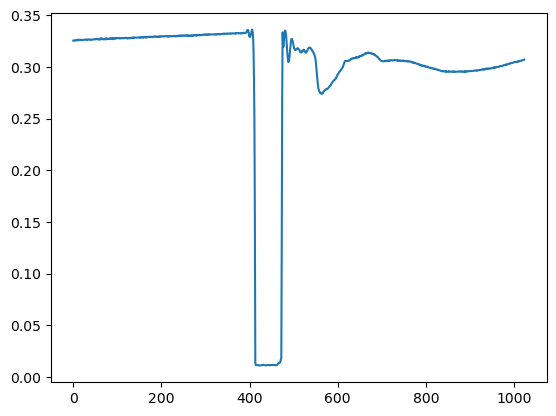

In [4]:
def do_plot(name, ax=None):
    if ax is None:
        fig, ax = plt.subplots()

    d = meas[name]
    ax.plot(d['adc1'])

do_plot('pi3hdx_clipline_offset_b_mesh_p0.6mm')

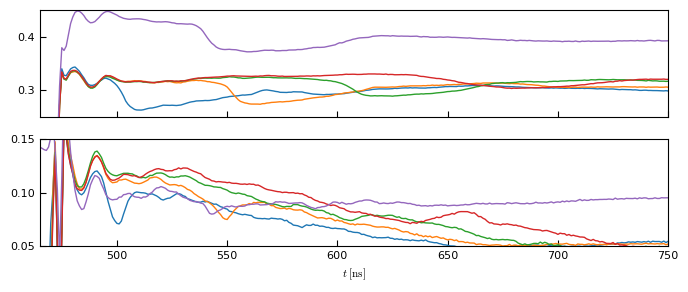

In [5]:
with plt.rc_context({
        'legend.fontsize': 8,
    # RC config from ChatGPT:
    "font.size": 8,  # General font size
    "axes.labelsize": 8,  # Axis labels
    "axes.titlesize": 8,  # Axis titles
    "xtick.labelsize": 8,  # X-axis tick labels
    "ytick.labelsize": 8,  # Y-axis tick labels
    "legend.fontsize": 8,  # Legend font size
    "figure.titlesize": 12,  # Overall figure title
    "mathtext.fontset": "cm",  # Use Computer Modern for math

    # Line and Marker settings
    "lines.linewidth": 1,
    "lines.markersize": 3,

    # Tick settings
    "xtick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.major.size": 4,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",

    # Axes settings
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",

    # Legend settings
    "legend.frameon": False,

    # Figure size for single-column figures in print (inches)
#    "figure.figsize": (3.5, 2.5),  # Adjust based on journal specifications
#    "figure.dpi": 300,  # High resolution for print

    # Savefig settings for high-quality output
    "savefig.dpi": 600,  # Ensures high-resolution images
    "savefig.bbox": "tight",  # Trim extra whitespace
    "savefig.transparent": True,  # Avoid background color
}):
    fig, axs = plt.subplots(2, 1, sharex=True, figsize=[7, 3])

    for name in [
            'pi3hdx_clipline_offset_b_mesh_p1.0mm',
            'pi3hdx_clipline_offset_b_mesh_p0.6mm',
            'pi3hdx_clipline_offset_b_mesh_p0.4mm',
            'pi3hdx_clipline_offset_b_mesh_p0.3mm',
            'pi3hdx_clipline_offset_b_mesh_p1.0mm_manip_short',
        ]:
        d = meas[name]
        axs[0].plot(d['adc1'])
        axs[1].plot(d['adc2'] - d['adc1'])

    axs[0].grid()
    axs[1].grid()
    axs[1].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[1].set_xlim([465, 750])
    axs[0].set_ylim([0.25, 0.45])
    axs[1].set_ylim([0.05, 0.15])
    fig.tight_layout()

#fig.savefig('../paper/fig_edge_risetime.pdf')

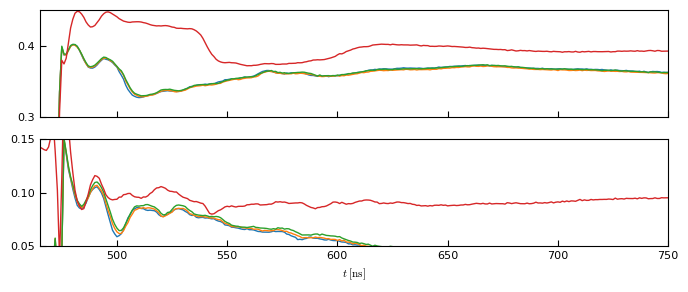

In [6]:
with plt.rc_context({
        'legend.fontsize': 8,
    # RC config from ChatGPT:
    "font.size": 8,  # General font size
    "axes.labelsize": 8,  # Axis labels
    "axes.titlesize": 8,  # Axis titles
    "xtick.labelsize": 8,  # X-axis tick labels
    "ytick.labelsize": 8,  # Y-axis tick labels
    "legend.fontsize": 8,  # Legend font size
    "figure.titlesize": 12,  # Overall figure title
    "mathtext.fontset": "cm",  # Use Computer Modern for math

    # Line and Marker settings
    "lines.linewidth": 1,
    "lines.markersize": 3,

    # Tick settings
    "xtick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.major.size": 4,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",

    # Axes settings
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",

    # Legend settings
    "legend.frameon": False,

    # Figure size for single-column figures in print (inches)
#    "figure.figsize": (3.5, 2.5),  # Adjust based on journal specifications
#    "figure.dpi": 300,  # High resolution for print

    # Savefig settings for high-quality output
    "savefig.dpi": 600,  # Ensures high-resolution images
    "savefig.bbox": "tight",  # Trim extra whitespace
    "savefig.transparent": True,  # Avoid background color
}):
    fig, axs = plt.subplots(2, 1, sharex=True, figsize=[7, 3])

    for name in [
            'pi3hdx_clipline_offset_a_mesh_p1.0mm_manip_scope_probe_none',
            'pi3hdx_clipline_offset_a_mesh_p1.0mm_manip_scope_probe_a',
            'pi3hdx_clipline_offset_a_mesh_p1.0mm_manip_scope_probe_b',
            'pi3hdx_clipline_offset_b_mesh_p1.0mm_manip_short',
        ]:
        d = meas[name]
        axs[0].plot(d['adc1'])
        axs[1].plot(d['adc2'] - d['adc1'])

    axs[0].grid()
    axs[1].grid()
    axs[1].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[1].set_xlim([465, 750])
    axs[0].set_ylim([0.30, 0.45])
    axs[1].set_ylim([0.05, 0.15])
    fig.tight_layout()

#fig.savefig('../paper/fig_edge_risetime.pdf')

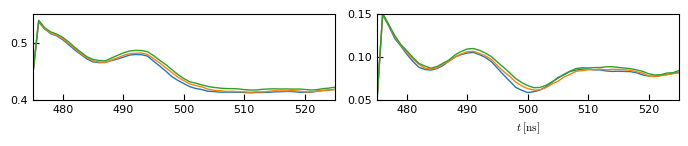

In [7]:
with plt.rc_context({
        'legend.fontsize': 8,
    # RC config from ChatGPT:
    "font.size": 8,  # General font size
    "axes.labelsize": 8,  # Axis labels
    "axes.titlesize": 8,  # Axis titles
    "xtick.labelsize": 8,  # X-axis tick labels
    "ytick.labelsize": 8,  # Y-axis tick labels
    "legend.fontsize": 8,  # Legend font size
    "figure.titlesize": 12,  # Overall figure title
    "mathtext.fontset": "cm",  # Use Computer Modern for math

    # Line and Marker settings
    "lines.linewidth": 1,
    "lines.markersize": 3,

    # Tick settings
    "xtick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.major.size": 4,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",

    # Axes settings
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",

    # Legend settings
    "legend.frameon": False,

    # Figure size for single-column figures in print (inches)
#    "figure.figsize": (3.5, 2.5),  # Adjust based on journal specifications
#    "figure.dpi": 300,  # High resolution for print

    # Savefig settings for high-quality output
    "savefig.dpi": 600,  # Ensures high-resolution images
    "savefig.bbox": "tight",  # Trim extra whitespace
    "savefig.transparent": True,  # Avoid background color
}):
    fig, axs = plt.subplots(1, 2, sharex=True, figsize=[7, 1.5])

    for name in [
            #'pi3hdx_clipline_offset_b_mesh_p1.0mm_manip_short',
            'pi3hdx_clipline_offset_a_mesh_p1.0mm_manip_scope_probe_none',
            'pi3hdx_clipline_offset_a_mesh_p1.0mm_manip_scope_probe_a',
            'pi3hdx_clipline_offset_a_mesh_p1.0mm_manip_scope_probe_b',
        ]:
        d = meas[name]
        axs[0].plot(d['adc2'])
        axs[1].plot(d['adc2'] - d['adc1'])

    axs[0].grid()
    axs[1].grid()
    axs[1].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[1].set_xlim([475, 525])
    axs[0].set_ylim([0.40, 0.55])
    axs[1].set_ylim([0.05, 0.15])
    fig.tight_layout()

#fig.savefig('../paper/fig_edge_risetime.pdf')

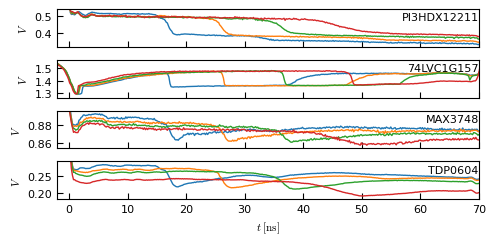

In [17]:
with plt.rc_context({
        'legend.fontsize': 8,
    # RC config from ChatGPT:
    "font.size": 8,  # General font size
    "axes.labelsize": 8,  # Axis labels
    "axes.titlesize": 8,  # Axis titles
    "xtick.labelsize": 8,  # X-axis tick labels
    "ytick.labelsize": 8,  # Y-axis tick labels
    "legend.fontsize": 8,  # Legend font size
    "figure.titlesize": 12,  # Overall figure title
    "mathtext.fontset": "cm",  # Use Computer Modern for math

    # Line and Marker settings
    "lines.linewidth": 1,
    "lines.markersize": 3,

    # Tick settings
    "xtick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.major.size": 4,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",

    # Axes settings
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",

    # Legend settings
    "legend.frameon": False,

    # Figure size for single-column figures in print (inches)
#    "figure.figsize": (3.5, 2.5),  # Adjust based on journal specifications
#    "figure.dpi": 300,  # High resolution for print

    # Savefig settings for high-quality output
    "savefig.dpi": 600,  # Ensures high-resolution images
    "savefig.bbox": "tight",  # Trim extra whitespace
    "savefig.transparent": True,  # Avoid background color
}):
    fig, axs = plt.subplots(4, 1, sharex=True, figsize=[5, 2.5])

    d = meas['74lvc_new2_mesh_p1.0mm']
    sampling_period_ns = 1000 / 168 / 32
    t = np.linspace(0, len(d['adc1'])*sampling_period_ns, len(d['adc1']))

    for ax, (chip, (chip_label, adc, shift)) in zip(axs, {
                             'pi3hdx': ('PI3HDX12211', 'adc2', 0),
                             '74lvc': ('74LVC1G157', 'adc1', 4),
                             'max3748': ('MAX3748', 'adc2', 0),
                             'tdp0604': ('TDP0604', 'adc2', 0)}.items()):
        low, high = 1000, -1000
        for name in [
                'run3_{chip}_mesh_p1.0mm',
                'run3_{chip}_mesh_p0.6mm',
                'run3_{chip}_mesh_p0.4mm',
                'run3_{chip}_mesh_p0.3mm',
            ]:
            d = meas[name.format(chip=chip)]
            v = d[adc]
            th = (v.min() + v.max()) / 2
            idx = np.argmax((v[:-1] >= th) & (v[1:] < th))
            t_off = idx*sampling_period_ns + shift
            ax.plot(t - t_off, v)

            v_slice = v[idx+10:idx+350]
            low = min(low, v_slice.min())
            high = max(high, v_slice.max())
            
        amp = high - low
        low -= 0.1*amp
        high += 0.1*amp
        ax.set_ylim([low, high])
        ax.set_ylabel('$V$')
        ax.set_title(chip_label, y=1.0, pad=-8, loc='right')
        ax.grid()
    axs[-1].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[-1].set_xlim([-2, 70])
    fig.tight_layout()

fig.savefig('../paper/fig_mesh_length.pdf')

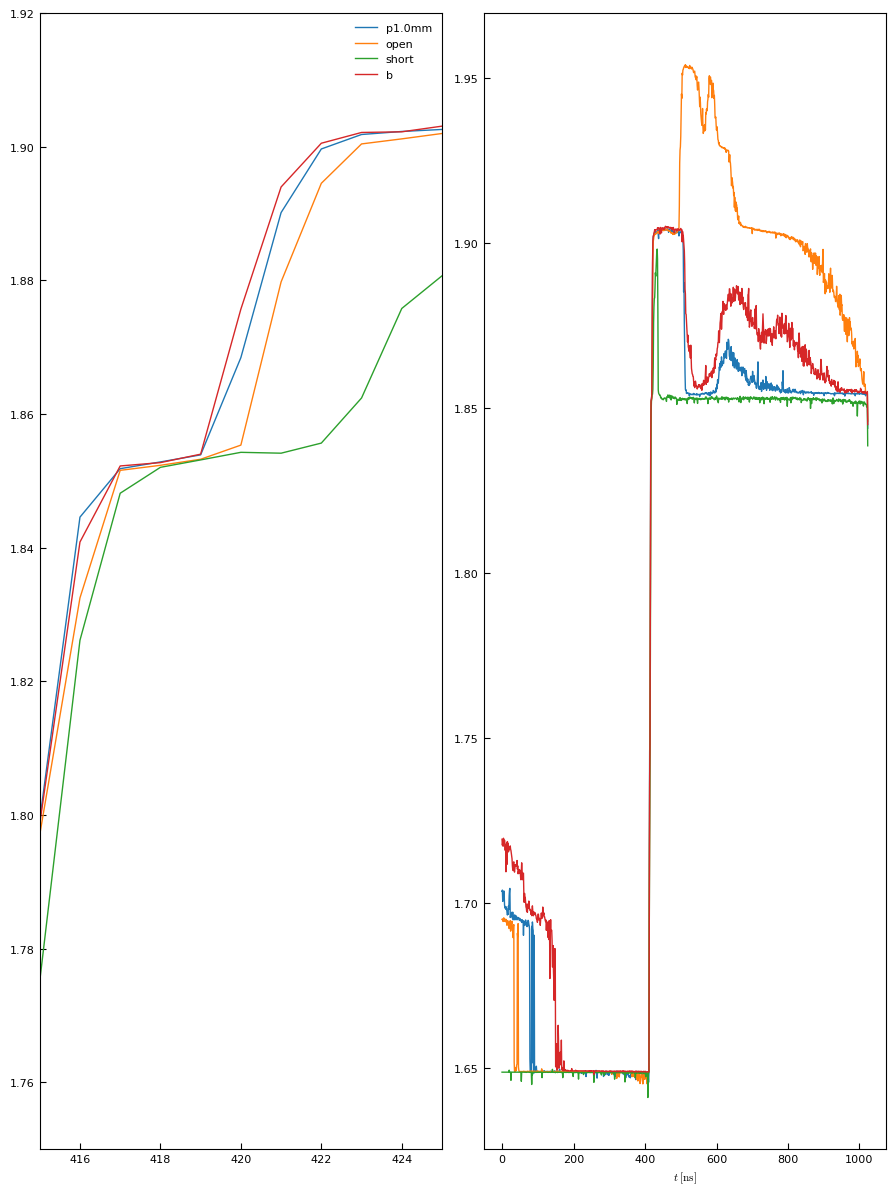

In [35]:
with plt.rc_context({
    'legend.fontsize': 8,
    # RC config from ChatGPT:
    "font.size": 8,  # General font size
    "axes.labelsize": 8,  # Axis labels
    "axes.titlesize": 8,  # Axis titles
    "xtick.labelsize": 8,  # X-axis tick labels
    "ytick.labelsize": 8,  # Y-axis tick labels
    "legend.fontsize": 8,  # Legend font size
    "figure.titlesize": 12,  # Overall figure title
    "mathtext.fontset": "cm",  # Use Computer Modern for math

    # Line and Marker settings
    "lines.linewidth": 1,
    "lines.markersize": 3,

    # Tick settings
    "xtick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.major.size": 4,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",

    # Axes settings
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",

    # Legend settings
    "legend.frameon": False,

    # Figure size for single-column figures in print (inches)
#    "figure.figsize": (3.5, 2.5),  # Adjust based on journal specifications
#    "figure.dpi": 300,  # High resolution for print

    # Savefig settings for high-quality output
    "savefig.dpi": 600,  # Ensures high-resolution images
    "savefig.bbox": "tight",  # Trim extra whitespace
    "savefig.transparent": True,  # Avoid background color
}):
    fig, axs = plt.subplots(1, 2, figsize=[9, 12])
    
    d = meas['74lvc_new2_mesh_p1.0mm']
    sampling_period_ns = 1000 / 168 / 32
    t = np.linspace(0, len(d['adc1'])*sampling_period_ns, len(d['adc1']))

    for name in [
            'tdp0604_new_avg_term_flip_mesh_p1.0mm',
            'tdp0604_new_avg_term_flip_mesh_1.0mm_open',
            #'tdp0604_new_avg_term_flip_mesh_1.0mm_open_fix_wire',
            'tdp0604_new_avg_term_flip_mesh_1.0mm_short',
            #'tdp0604_new_avg_term_flip_mesh_1.0mm_probe_a',
            'tdp0604_new_avg_term_flip_mesh_1.0mm_probe_b',
            #'tdp0604_new_avg_term_flip_mesh_1.0mm_probe_no',
        ]:
        d = meas[name]
        _1, _, foo = name.rpartition('_')
        axs[0].plot(d['adc1'], label=foo)
        axs[1].plot(d['adc1'], label=foo)
        #axs[1].plot(d['adc2'] - d['adc1'])

    axs[0].legend()
    axs[0].grid()
    axs[1].grid()
    axs[1].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[0].set_xlim([415, 425])
    #axs[1].set_xlim([505, 515])
    axs[0].set_ylim([1.75, 1.92])
    #axs[1].set_ylim([1.80, 2.00])
    fig.tight_layout()

#fig.savefig('../paper/fig_edge_risetime.pdf')

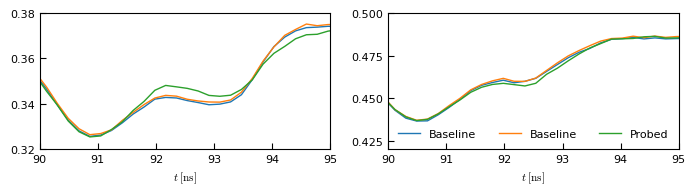

In [36]:
with plt.rc_context({
    'legend.fontsize': 8,
    # RC config from ChatGPT:
    "font.size": 8,  # General font size
    "axes.labelsize": 8,  # Axis labels
    "axes.titlesize": 8,  # Axis titles
    "xtick.labelsize": 8,  # X-axis tick labels
    "ytick.labelsize": 8,  # Y-axis tick labels
    "legend.fontsize": 8,  # Legend font size
    "figure.titlesize": 12,  # Overall figure title
    "mathtext.fontset": "cm",  # Use Computer Modern for math

    # Line and Marker settings
    "lines.linewidth": 1,
    "lines.markersize": 3,

    # Tick settings
    "xtick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.major.size": 4,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",

    # Axes settings
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",

    # Legend settings
    "legend.frameon": False,

    # Figure size for single-column figures in print (inches)
#    "figure.figsize": (3.5, 2.5),  # Adjust based on journal specifications
#    "figure.dpi": 300,  # High resolution for print

    # Savefig settings for high-quality output
    "savefig.dpi": 600,  # Ensures high-resolution images
    "savefig.bbox": "tight",  # Trim extra whitespace
    "savefig.transparent": True,  # Avoid background color
}):
    fig, axs = plt.subplots(1, 2, figsize=[7, 2])
    
    d = meas['74lvc_new2_mesh_p1.0mm']
    sampling_period_ns = 1000 / 168 / 32
    t = np.linspace(0, len(d['adc1'])*sampling_period_ns, len(d['adc1']))

    for name, label in {
            'pi3hdx_manip_test2_baseline': 'Baseline',
            'pi3hdx_manip_test2_baseline2': 'Baseline',
            'pi3hdx_manip_test2_scope_probe': 'Probed',
        }.items():
        d = meas[name]
        _1, _, foo = name.rpartition('_')
        axs[0].plot(t[470:550], d['adc1'][470:550], label=label)
        axs[1].plot(t[470:550], d['adc2'][470:550], label=label)
        #axs[1].plot(d['adc2'] - d['adc1'])

    axs[1].legend(loc='lower right', ncol=3)
    axs[1].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[0].set_xlim([90, 95])
    axs[1].set_xlim([90, 95])
    axs[0].set_ylim([0.32, 0.38])
    axs[1].set_ylim([0.42, 0.50])
    axs[0].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[1].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[0].grid()
    axs[1].grid()
    fig.tight_layout()

#fig.savefig('../paper/fig_probe_shape.pdf')

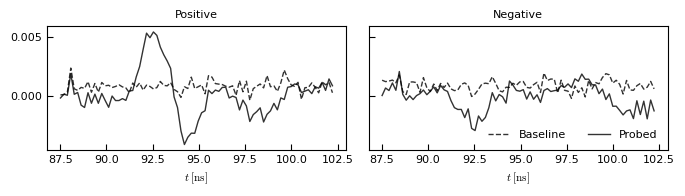

In [43]:
with plt.rc_context({
    'legend.fontsize': 8,
    # RC config from ChatGPT:
    "font.size": 8,  # General font size
    "axes.labelsize": 8,  # Axis labels
    "axes.titlesize": 8,  # Axis titles
    "xtick.labelsize": 8,  # X-axis tick labels
    "ytick.labelsize": 8,  # Y-axis tick labels
    "legend.fontsize": 8,  # Legend font size
    "figure.titlesize": 12,  # Overall figure title
    "mathtext.fontset": "cm",  # Use Computer Modern for math

    # Line and Marker settings
    "lines.linewidth": 1,
    "lines.markersize": 3,

    # Tick settings
    "xtick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.major.size": 4,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",

    # Axes settings
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",

    # Legend settings
    "legend.frameon": False,

    # Figure size for single-column figures in print (inches)
#    "figure.figsize": (3.5, 2.5),  # Adjust based on journal specifications
#    "figure.dpi": 300,  # High resolution for print

    # Savefig settings for high-quality output
    "savefig.dpi": 600,  # Ensures high-resolution images
    "savefig.bbox": "tight",  # Trim extra whitespace
    "savefig.transparent": True,  # Avoid background color
}):
    fig, axs = plt.subplots(1, 2, figsize=[7, 2], sharey=True)
    
    d = meas['74lvc_new2_mesh_p1.0mm']
    sampling_period_ns = 1000 / 168 / 32
    t = np.linspace(0, len(d['adc1'])*sampling_period_ns, len(d['adc1']))

    for name, (label, linestyle) in {
            'pi3hdx_manip_test2_baseline2': ('Baseline', '--'),
            'pi3hdx_manip_test2_scope_probe': ('Probed', '-'),
        }.items():
        d_b = meas['pi3hdx_manip_test2_baseline']
        d = meas[name]
        _1, _, foo = name.rpartition('_')
        a, b = 470, 550
        axs[0].plot(t[a:b], (d['adc1'] - d_b['adc1'])[a:b], label=label, color='black', alpha=0.8, linestyle=linestyle)
        axs[1].plot(t[a:b], (d['adc2'] - d_b['adc2'])[a:b], label=label, color='black', alpha=0.8, linestyle=linestyle)
        #axs[1].plot(d['adc2'] - d['adc1'])

    axs[1].legend(loc='lower right', ncol=3)
    axs[1].set_xlabel(r'$t\;[\mathrm{ns}]$')
    #axs[0].set_xlim([90, 100])
    #axs[1].set_xlim([90, 100])
    axs[0].set_title('Positive')
    axs[1].set_title('Negative')
    #axs[0].set_ylim([0.32, 0.38])
    #axs[1].set_ylim([0.42, 0.50])
    axs[0].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[1].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[0].grid()
    axs[1].grid()
    fig.tight_layout()

#fig.savefig('../paper/fig_probe_shape.pdf')

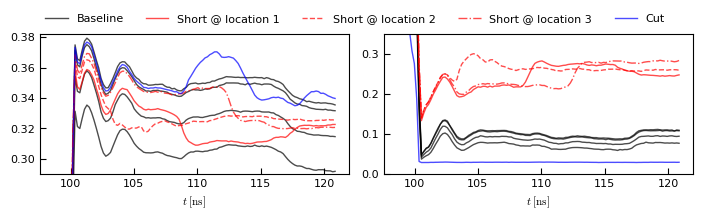

In [41]:
with plt.rc_context({
    'legend.fontsize': 8,
    # RC config from ChatGPT:
    "font.size": 8,  # General font size
    "axes.labelsize": 8,  # Axis labels
    "axes.titlesize": 8,  # Axis titles
    "xtick.labelsize": 8,  # X-axis tick labels
    "ytick.labelsize": 8,  # Y-axis tick labels
    "legend.fontsize": 8,  # Legend font size
    "figure.titlesize": 12,  # Overall figure title
    "mathtext.fontset": "cm",  # Use Computer Modern for math

    # Line and Marker settings
    "lines.linewidth": 1,
    "lines.markersize": 3,

    # Tick settings
    "xtick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.major.size": 4,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",

    # Axes settings
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",

    # Legend settings
    "legend.frameon": False,

    # Figure size for single-column figures in print (inches)
#    "figure.figsize": (3.5, 2.5),  # Adjust based on journal specifications
#    "figure.dpi": 300,  # High resolution for print

    # Savefig settings for high-quality output
    "savefig.dpi": 600,  # Ensures high-resolution images
    "savefig.bbox": "tight",  # Trim extra whitespace
    "savefig.transparent": True,  # Avoid background color
}):
    fig, axs = plt.subplots(1, 2, figsize=[7, 2])
    
    d = meas['74lvc_new2_mesh_p1.0mm']
    sampling_period_ns = 1000 / 168 / 32
    t = np.linspace(0, len(d['adc1'])*sampling_period_ns, len(d['adc1']))

    ivl_start, ivl_end = 530, 650

    legend_names = []
    legend_handles = []
    for name, (label, color, linestyle) in {
            'run3_pi3hdx_manip_baseline1': ('Baseline', 'black', '-'),
            'run3_pi3hdx_manip_baseline2': ('', 'black', '-'),
            'run3_pi3hdx_manip_baseline3': ('', 'black', '-'),
            'run3_pi3hdx_manip_baseline4': ('', 'black', '-'),
            'run3_pi3hdx_manip_short1':    ('Short @ location 1', 'red', '-'),
            'run3_pi3hdx_manip_short2':    ('Short @ location 2', 'red', '--'),
            'run3_pi3hdx_manip_short3':    ('Short @ location 3', 'red', '-.'),
            'run3_pi3hdx_manip_cut':       ('Cut', 'blue', '-'),
        }.items():
        d = meas[name]
        _1, _, foo = name.rpartition('_')
        h, = axs[0].plot(t[ivl_start:ivl_end], d['adc1'][ivl_start:ivl_end], color=color, alpha=0.7, linestyle=linestyle)
        h, = axs[1].plot(t[ivl_start:ivl_end], d['adc2'][ivl_start:ivl_end], color=color, alpha=0.7, linestyle=linestyle)
        if label:
            legend_handles.append(h)
            legend_names.append(label)
        #axs[1].plot(d['adc2'] - d['adc1'])

    fig.tight_layout()
    fig.subplots_adjust(top=0.8, bottom=0.1)
    fig.legend(legend_handles, legend_names, loc='upper center', ncol=5, bbox_to_anchor=[0.5, 0.95])
    #axs[1].legend(loc='lower right', ncol=3)
    axs[1].set_xlabel(r'$t\;[\mathrm{ns}]$')
    #axs[0].set_xlim([87, 102])
    #axs[1].set_xlim([87, 102])
    axs[0].set_ylim([0.29, 0.382])
    axs[1].set_ylim([0.00, 0.35])
    axs[0].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[1].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[0].grid()
    axs[1].grid()

fig.savefig('../paper/fig_manip_shape.pdf')

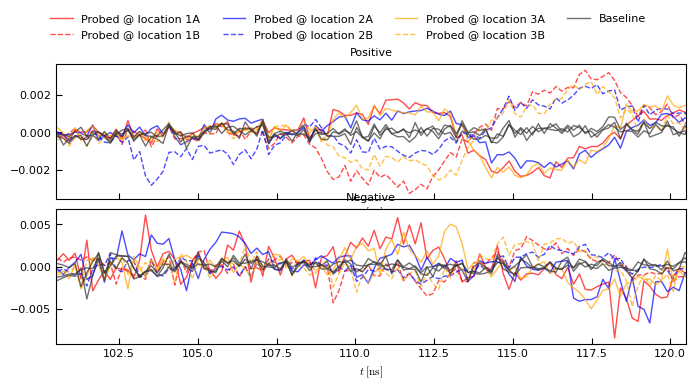

In [23]:
with plt.rc_context({
    'legend.fontsize': 8,
    # RC config from ChatGPT:
    "font.size": 8,  # General font size
    "axes.labelsize": 8,  # Axis labels
    "axes.titlesize": 8,  # Axis titles
    "xtick.labelsize": 8,  # X-axis tick labels
    "ytick.labelsize": 8,  # Y-axis tick labels
    "legend.fontsize": 8,  # Legend font size
    "figure.titlesize": 12,  # Overall figure title
    "mathtext.fontset": "cm",  # Use Computer Modern for math

    # Line and Marker settings
    "lines.linewidth": 1,
    "lines.markersize": 3,

    # Tick settings
    "xtick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.major.size": 4,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",

    # Axes settings
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",

    # Legend settings
    "legend.frameon": False,

    # Figure size for single-column figures in print (inches)
#    "figure.figsize": (3.5, 2.5),  # Adjust based on journal specifications
#    "figure.dpi": 300,  # High resolution for print

    # Savefig settings for high-quality output
    "savefig.dpi": 600,  # Ensures high-resolution images
    "savefig.bbox": "tight",  # Trim extra whitespace
    "savefig.transparent": True,  # Avoid background color
}):
    fig, axs = plt.subplots(2, 1, figsize=[7, 4], sharex=True)
    
    d = meas['run4_pi3hdx_manip_baseline1']
    sampling_period_ns = 1000 / 168 / 32
    t = np.linspace(0, len(d['adc1'])*sampling_period_ns, len(d['adc1']))

    fig_handles, fig_labels = [], []
    for name, (label, color, linestyle, linewidth) in {
            'run4_pi3hdx_manip_probe1a': ('Probed @ location 1A', 'red', '-', 1),
            'run4_pi3hdx_manip_probe1b': ('Probed @ location 1B', 'red', '--', 1),
            'run4_pi3hdx_manip_probe2a': ('Probed @ location 2A', 'blue', '-', 1),
            'run4_pi3hdx_manip_probe2b': ('Probed @ location 2B', 'blue', '--', 1),
            'run4_pi3hdx_manip_probe3b': ('Probed @ location 3A', 'orange', '-', 1), # Note: Location 3 A/B labels are flipped on PCB and source data
            'run4_pi3hdx_manip_probe3a': ('Probed @ location 3B', 'orange', '--', 1),
            'run4_pi3hdx_manip_baseline3': ('Baseline', '#333', '-', 1),
            'run4_pi3hdx_manip_baseline1': ('', '#333', '-', 1),
            'run4_pi3hdx_manip_baseline4': ('', '#333', '-', 1),
        }.items():
        d_b = meas['run4_pi3hdx_manip_baseline2']
        d = meas[name]
        _1, _, foo = name.rpartition('_')
        a, b = 540, 650
        x = 540
        y = x + (b - a)
        delta1 = (d['adc1'] - d_b['adc1'])[a:b]
        delta2 = (d['adc2'] - d_b['adc2'])[x:y]
        delta1 -= delta1.mean()
        delta2 -= delta2.mean()
        h, = axs[0].plot(t[a:b], delta1, color=color, alpha=0.7, linestyle=linestyle, linewidth=linewidth)
        h, = axs[1].plot(t[x:y], delta2, color=color, alpha=0.7, linestyle=linestyle, linewidth=linewidth)
        if label:
            fig_handles.append(h)
            fig_labels.append(label)
        #axs[1].plot(d['adc2'] - d['adc1'])

    fig.tight_layout()
    fig.subplots_adjust(top=0.8, bottom=0.1)
    fig.legend(fig_handles, fig_labels, loc='upper center', ncol=4, bbox_to_anchor=[0.5, 0.95])
    axs[1].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[0].set_xlim([100.5, 120.5])
    #axs[1].set_xlim([90, 100])
    axs[0].set_title('Positive')
    axs[1].set_title('Negative')
    #axs[0].set_ylim([-0.005, 0.005])
    #axs[1].set_ylim([-0.01, 0.02])
    axs[0].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[1].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[0].grid()
    axs[1].grid()

fig.savefig('../paper/fig_probe_shape.pdf')

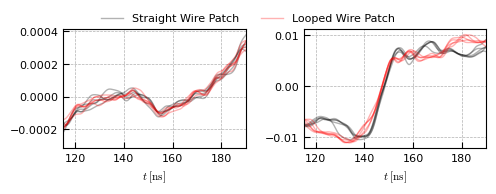

In [9]:
with plt.rc_context({
    'legend.fontsize': 8,
    # RC config from ChatGPT:
    "font.size": 8,  # General font size
    "axes.labelsize": 8,  # Axis labels
    "axes.titlesize": 8,  # Axis titles
    "xtick.labelsize": 8,  # X-axis tick labels
    "ytick.labelsize": 8,  # Y-axis tick labels
    "legend.fontsize": 8,  # Legend font size
    "figure.titlesize": 12,  # Overall figure title
    "mathtext.fontset": "cm",  # Use Computer Modern for math

    # Line and Marker settings
    "lines.linewidth": 1,
    "lines.markersize": 3,

    # Tick settings
    "xtick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.major.size": 4,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",

    # Axes settings
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",

    # Legend settings
    "legend.frameon": False,

    # Figure size for single-column figures in print (inches)
#    "figure.figsize": (3.5, 2.5),  # Adjust based on journal specifications
#    "figure.dpi": 300,  # High resolution for print

    # Savefig settings for high-quality output
    "savefig.dpi": 600,  # Ensures high-resolution images
    "savefig.bbox": "tight",  # Trim extra whitespace
    "savefig.transparent": True,  # Avoid background color
}):
    fig, axs = plt.subplots(1, 2, figsize=[5, 1.7])
    
    d = meas['long_sample_b_pre_mod_10']
    sampling_period_ns = 1000 / 168 / 32
    t = np.linspace(0, len(d['adc1'])*sampling_period_ns, len(d['adc1']))

    fig_handles, fig_labels = [], []
    for name, (label, color, linestyle, linewidth) in {
            'long_sample_b_post_demod_1': ('Straight Wire Patch', 'black', '-', 1),
            'long_sample_b_post_demod_2': ('', 'black', '-', 1),
            'long_sample_b_post_demod_4': ('', 'black', '-', 1),
            'long_sample_b_post_demod_6': ('', 'black', '-', 1),
            'long_sample_b_post_demod_8': ('', 'black', '-', 1),
            'long_sample_b_post_2modb_1': ('Looped Wire Patch', 'red', '-', 1),
            'long_sample_b_post_2modb_2': ('', 'red', '-', 1),
            'long_sample_b_post_2modb_4': ('', 'red', '-', 1),
            'long_sample_b_post_2modb_6': ('', 'red', '-', 1),
            'long_sample_b_post_2modb_8': ('', 'red', '-', 1),
        }.items():
        d_b = meas['long_sample_b_pre_mod_10']
        d = meas[name]
        _1, _, foo = name.rpartition('_')
        a, b = 600, -1
        x = 600
        y = x + (b - a)
        delta1 = (d['adc1'] - d_b['adc1'])[a:b]
        delta2 = (d['adc2'] - d_b['adc2'])[x:y]
        delta1 -= delta1.mean()
        delta2 -= delta2.mean()
        lam = 10
        spl1 = interpolate.make_smoothing_spline(t[a:b], delta1, lam=lam)
        spl2 = interpolate.make_smoothing_spline(t[x:y], delta2, lam=lam)
        h, = axs[0].plot(t[a:b], spl1(t[a:b]), color=color, alpha=0.3, linestyle=linestyle, linewidth=linewidth)
        h, = axs[1].plot(t[x:y], spl2(t[x:y]), color=color, alpha=0.3, linestyle=linestyle, linewidth=linewidth)
        if label:
            fig_handles.append(h)
            fig_labels.append(label)
        #axs[1].plot(d['adc2'] - d['adc1'])

    fig.tight_layout()
    fig.subplots_adjust(top=0.8, bottom=0.1)
    fig.legend(fig_handles, fig_labels, loc='upper center', ncol=4, bbox_to_anchor=[0.5, 0.95])
    axs[1].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[0].set_xlim([115, 190])
    axs[1].set_xlim([115, 190])
    #axs[0].set_title('Positive')
    #axs[1].set_title('Negative')
    #axs[0].set_ylim([-0.005, 0.005])
    #axs[1].set_ylim([-0.01, 0.02])
    axs[0].set_xlabel(r'$t\;[\mathrm{ns}]$')
    axs[1].set_xlabel(r'$t\;[\mathrm{ns}]$')
    #axs[0].grid()
    #axs[1].grid()
    
fig.savefig('../paper/fig_drill_mod_shape.pdf')